### Step 1: Setup and Reproducability

In [1002]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

RANDOM_STATE=42
np.random.seed(RANDOM_STATE)
sns.set_theme(style='whitegrid')

### Step 2: Exploratory Data Analysis

Dataset data overview


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
2,Unbranded,HOGO BOSS cologne For Men 3.4 oz,Eau de Toilette,100.00,US $100.00,10.0,More than 10 available / 27 sold,27.0,"May 22, 2024 21:55:43 PDT","Dearborn, Michigan, United States"
3,Giorgio Armani,Acqua Di Gio by Giorgio Armani 6.7 Fl oz Eau D...,Eau de Toilette,NaN,US $44.99/ea,2.0,2 available / 159 sold,159.0,"May 24, 2024 03:30:43 PDT","Reinholds, Pennsylvania, United States"
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,NaN,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"
5,Multiple Brands,Men's Perfume Sampler 10pcs Sample Vials Desig...,Perfume,14.99,US $14.99,10.0,More than 10 available / 79 sold,79.0,"May 23, 2024 06:57:41 PDT","Houston, Texas, United States"
6,Maison Alhambra,Glacier Bold by Maison Alhambra 3.4oz EDP for ...,Eau de Parfum,30.99,US $30.99/ea,9.0,9 available / 39 sold,39.0,"May 16, 2024 13:42:49 PDT","Englewood Cliffs, New Jersey, United States"
7,Unbranded,Parfums De-Marly-Haltane Eau de Parfum spray 4...,Eau de Parfum,85.00,US $85.00,NaN,Last One / 6 sold,7654.0,"May 24, 2024 00:10:39 PDT","Ithaca, New York, United States"
8,Unbranded,Hawas for him Eau De Parfum By Rasasi 100ml 3....,/,15.89,US $15.89,10.0,10 available / 17 sold,17.0,"May 24, 2024 09:08:14 PDT","shanghai, China"
9,Gucci,Gucci Guilty for Him - Classic 3oz Eau de Toil...,Eau de Parfum,49.99,US $49.99/ea,8.0,8 available / 68 sold,68.0,"May 23, 2024 07:21:23 PDT","Dearborn Heights, Michigan, United States"


Dataset info overview
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item_Name          999 non-null    str    
 1   details            1000 non-null   str    
 2   Catatory           997 non-null    str    
 3   price              995 non-null    float64
 4   priceWithCurrency  999 non-null    str    
 5   available          889 non-null    float64
 6   text               997 non-null    str    
 7   sold               992 non-null    float64
 8   lastUpdated        947 non-null    str    
 9   itemLocation       1000 non-null   str    
dtypes: float64(3), str(7)
memory usage: 78.3 KB


None

Missing values check


Item_Name              1
details                0
Catatory               3
price                  5
priceWithCurrency      1
available            111
text                   3
sold                   8
lastUpdated           53
itemLocation           0
dtype: int64

Duplicate values check


np.int64(0)

Summary statistics


,count,mean,std,min,25%,50%,75%,max
price,995.0,46.433467,35.551712,3.0,22.99,35.71,59.00,259.09
available,889.0,20.046119,61.547985,2.0,5.00,10.00,10.00,842.00
sold,992.0,775.246976,3211.433298,1.0,14.00,49.50,324.75,54052.00


Understanding distribution of data


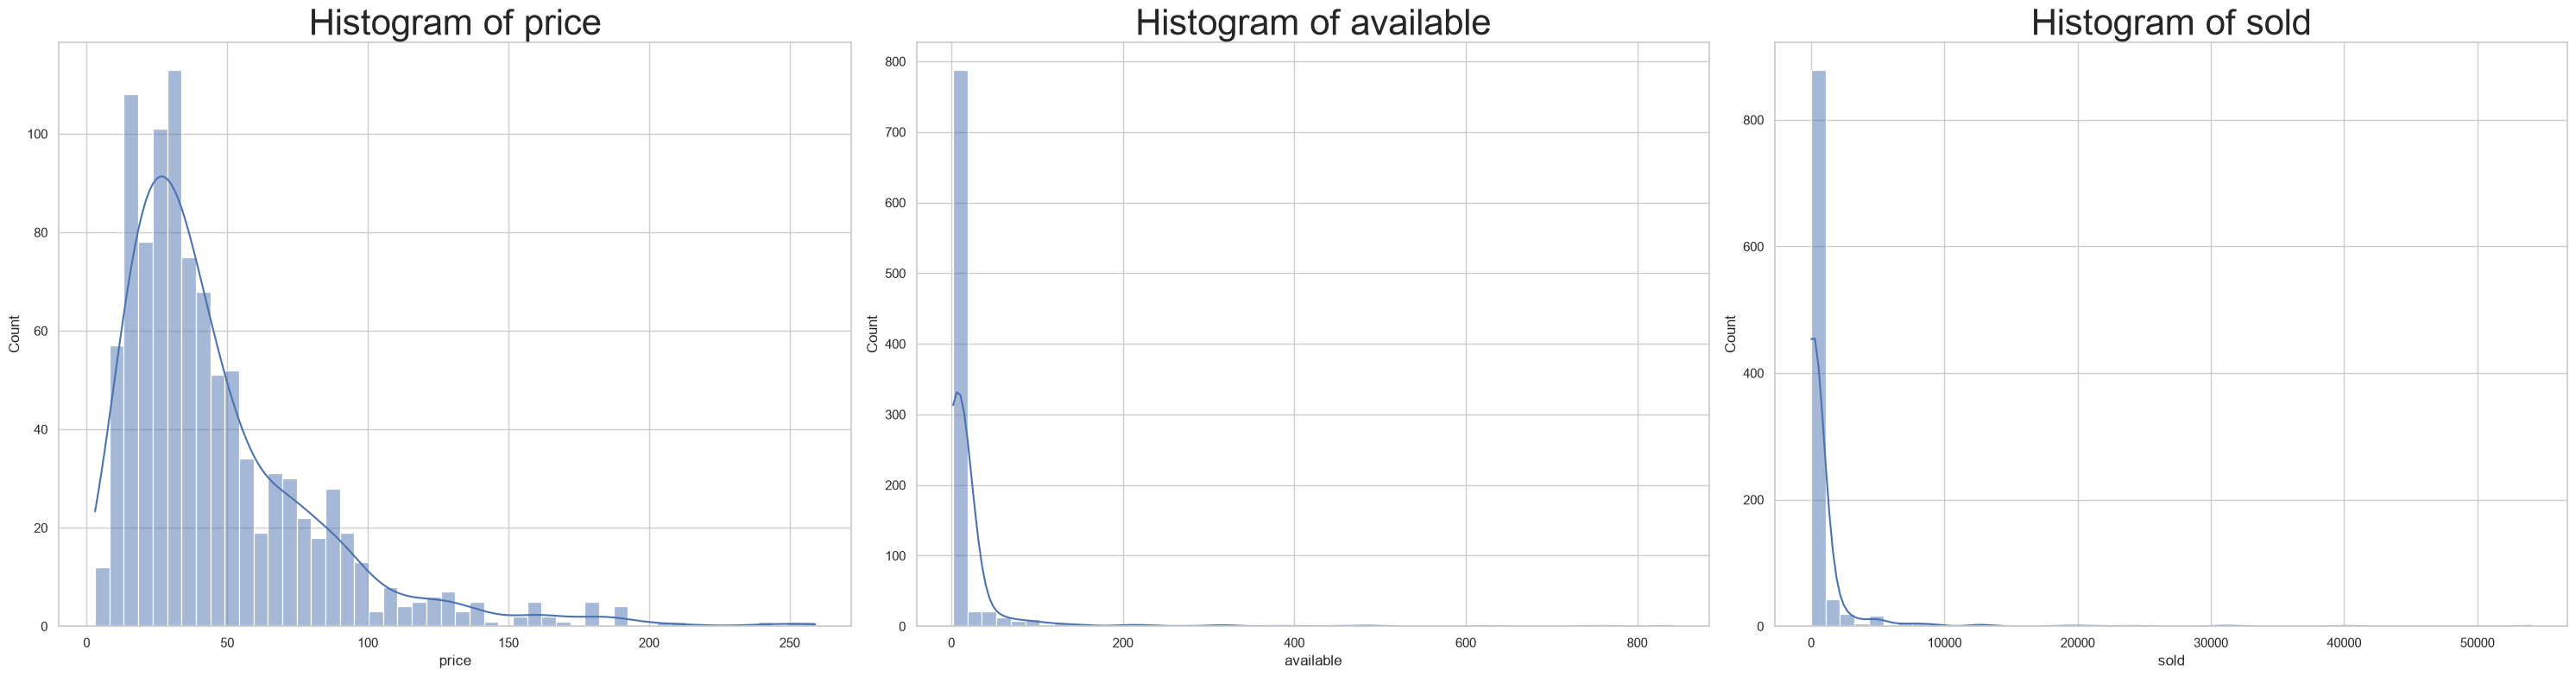

,feature,outliers_raw,outliers_after_log
0,price,54,5
1,available,101,89
2,sold,136,2


In [1003]:
df = pd.read_csv('Sales-[5444].csv')
print("Dataset data overview")
display(df.head(10))

print("Dataset info overview")
display(df.info())

print("Missing values check")
display(df.isna().sum())

print("Duplicate values check")
display(df.duplicated().sum())

print("Summary statistics")
display(df.describe().T)

print("Understanding distribution of data")
numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns.to_list()

fig, axes = plt.subplots(1, len(numerical_columns), figsize=(10 * len(numerical_columns), 8))
for i, column in enumerate(numerical_columns):
    sns.histplot(df[column], bins=50, kde=True, ax=axes[i])
    axes[i].set_title(f"Histogram of {column}", fontsize=30)
plt.tight_layout()
plt.show()

# data is abnormally distributed so check for outlies using 1.5iqr
def detect_outliers(s, k=1.5):
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

summary = []
for col in numerical_columns:
    s = df[col]
    log_s = np.log1p(s) if (s.dropna() > -1).all() else np.nan
    summary.append({
        'feature': col,
        'outliers_raw': detect_outliers(s).sum(),
        'outliers_after_log': detect_outliers(log_s).sum() if isinstance(log_s, pd.Series) else 'n/a (values <= -1)',
    })

pd.DataFrame(summary)

### Step 3: Data Preprocessing
The results above show that:
- the dataset contains missing values and outliers
- no duplicate data
- irrelevant columns (for the purpose of this project) and data in the wrong format such as the the `lastUpdated` field being of type string instead of text

The above stated will all be handled accordingly

In [1004]:
# 1. missing values
# identify rows containing the missing values

# item name - investigate and check if manual replacement by inference is possible (from details field)
display(df[df['Item_Name'].isnull()])
display(df[df['Catatory'].isin(['Eau de Parfum'])])
df.loc[567, 'Item_Name'] = 'Versace'

# Catatory - investigate and check if manual replacement by inference is possible (from details field)
display(df[df['Catatory'].isnull()])
replacements = {81: 'Cologne', 138: 'Cologne', 606: 'Eau de Parfum'}
for k, v in replacements.items():
    df.loc[k, 'Catatory'] = v

# price an sold columns (recovering from already exisiting data)
# - price
price_with_currency = (df["priceWithCurrency"].str.extract(r"\$([\d,\.]+)")[0]
         .str.replace(",", "").astype(float))
df['price'] = df['price'].fillna(price_with_currency)

# - sold - recovering from the text field
sold_text = (df["text"].str.extract(r"([\d,]+)\s+sold")[0]
              .str.replace(",", "").astype(float))
df['sold'] = df['sold'].fillna(sold_text)

# price with currency
display(df[df['priceWithCurrency'].isna()])
df.loc[4, 'priceWithCurrency'] = 'US $16.91'

# updating stock (available)
df.loc[df["text"].str.lower().str.startswith("last one", na=False) & df['available'].isna(), "available"] = 1
# Flags preserve information that imputation would erase
df["stock_censored"] = df["text"].str.contains("More than", na=False).astype(int)
df["stock_unknown"]  = df["available"].isna().astype(int)
df["available"] = df["available"].fillna(df["available"].median())

print("New missing values count")
display(df.isna().sum())

,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
567,NaN,Versace Pour Homme Oud Noir 3.4 oz EDP Cologne...,Eau de Parfum,55.16,US $55.16/ea,NaN,"Limited quantity available / 3,110 sold",3110.0,"May 24, 2024 07:53:50 PDT","Hackensack, New Jersey, United States"


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
0,Dior,Christian Dior Sauvage Men's EDP 3.4 oz Fragra...,Eau de Parfum,84.99,US $84.99/ea,10.0,More than 10 available / 116 sold,NaN,"May 24, 2024 10:03:04 PDT","Allen Park, Michigan, United States"
1,AS SHOW,A-v-entus Eau de Parfum 3.3 oz 100ML Millesime...,Eau de Parfum,NaN,US $109.99,8.0,8 available / 48 sold,48.0,"May 23, 2024 23:07:49 PDT","Atlanta, Georgia, Canada"
6,Maison Alhambra,Glacier Bold by Maison Alhambra 3.4oz EDP for ...,Eau de Parfum,30.99,US $30.99/ea,9.0,9 available / 39 sold,39.0,"May 16, 2024 13:42:49 PDT","Englewood Cliffs, New Jersey, United States"
7,Unbranded,Parfums De-Marly-Haltane Eau de Parfum spray 4...,Eau de Parfum,85.00,US $85.00,NaN,Last One / 6 sold,7654.0,"May 24, 2024 00:10:39 PDT","Ithaca, New York, United States"
9,Gucci,Gucci Guilty for Him - Classic 3oz Eau de Toil...,Eau de Parfum,49.99,US $49.99/ea,8.0,8 available / 68 sold,68.0,"May 23, 2024 07:21:23 PDT","Dearborn Heights, Michigan, United States"
...,...,...,...,...,...,...,...,...,...,...
975,Givenchy,Givenchy Gentleman Reserve Privee 3.3 oz Eau d...,Eau de Parfum,80.00,US $80.00/ea,10.0,10 available / 197 sold,197.0,"May 24, 2024 03:20:57 PDT","Katy, Texas, United States"
978,Dolce&Gabbana,"Dolce & Gabbana ""K (KING) INTENSE"",3.3oz, Men,...",Eau de Parfum,91.00,US $91.00,3.0,3 available / 1 sold,1.0,"May 02, 2024 19:37:12 PDT","Manor, Texas, United States"
982,Unbranded,VERSE ADONIS Pour Homme cologne for men 3.4oz,Eau de Parfum,13.99,US $13.99,10.0,More than 10 available / 9 sold,9.0,"Apr 28, 2024 20:19:23 PDT","Dearborn, Michigan, United States"
983,Carolina Herrera,Bad Boy Le Parfum by Carolina Herrera 3.4 oz. ...,Eau de Parfum,59.99,US $59.99/ea,10.0,10 available / 496 sold,496.0,"May 19, 2024 16:41:48 PDT","Katy, Texas, United States"


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
81,Calvin Klein,Ck One by Calvin Klein Cologne Perfume Unisex ...,NaN,23.89,US $23.89/ea,NaN,"Limited quantity available / 54,052 sold",54052.0,"May 24, 2024 03:59:39 PDT","Hackensack, New Jersey, United States"
138,AS SHOW,Bleu De Eau de parfum EDP 100ml 3.4 oz Cologne...,NaN,89.99,US $89.99,5.0,5 available / 5 sold,5.0,"May 14, 2024 20:43:05 PDT","New York,United States, Hong Kong"
606,Milestone Perfumes,Intimation By Milestone Eau de Parfum 3.4 oz Men,NaN,19.89,US $19.89,10.0,More than 10 available / 21 sold,21.0,"May 24, 2024 10:13:17 PDT","Miami, Florida, United States"


,Item_Name,details,Catatory,price,priceWithCurrency,available,text,sold,lastUpdated,itemLocation
4,Lattafa,Lattafa Men's Hayaati Al Maleky EDP Spray 3.4 ...,Fragrances,16.91,NaN,NaN,Limited quantity available / 156 sold,156.0,"May 24, 2024 07:56:25 PDT","Brooklyn, New York, United States"


New missing values count


Item_Name             0
details               0
Catatory              0
price                 0
priceWithCurrency     0
available             0
text                  3
sold                  6
lastUpdated          53
itemLocation          0
stock_censored        0
stock_unknown         0
dtype: int64

In [1005]:
# 2. data inconsistency 
# currency consistency - some rows are priced in canadian dollars
df['currency'] = df['priceWithCurrency'].str.extract(r"^(\w+)\s*\$")[0]
display(df['currency'].unique())
display(df.query('currency == "C"')[['price', 'lastUpdated']])
CAD_TO_USD = 0.73 # as of May 2024
df.loc[df['currency'] == 'C', 'price'] *= CAD_TO_USD

# fix column data types
# - last updated column
df['lastUpdated'] = pd.to_datetime(
    df["lastUpdated"].str.replace(r"\s+P[DS]T$", "", regex=True),
    format="%b %d, %Y %H:%M:%S", errors="coerce")

snapshot = df['lastUpdated'].max()
df["days_since_update"] = (snapshot - df["lastUpdated"]).dt.total_seconds() / 86400
df["days_since_update"] = df["days_since_update"].fillna(df["days_since_update"].median())

# available and sold column - while these are discrete quantities, they cannot be converted to int because of the present of null values (np.NaN) which is of type float

# 4. normalizing the categories
print("Initial unique catergories")
display(df['Catatory'].unique())
df["Catatory"].value_counts()

def group_category(c):
    if pd.isna(c): return "Other"
    c = c.lower().strip()
    if "toil" in c or c == "edt": return "Eau de Toilette"
    if any(k in c for k in ["parfum", "perfume", "extrait", "elixir"]) or c == "edp":
        return "Eau de Parfum"
    if "cologne" in c or c in {"edc", "aftershave", "splash-on"}:   return "Cologne"
    return "Other"

df["Catatory"] = df["Catatory"].apply(group_category)
df["Catatory"].value_counts()

print("Normalized categories")
display(df['Catatory'].unique())

# 5. rename columns and remove whitespace from categories column
df = df.rename(columns={
    'Item_Name': 'item_name',
    'Catatory': 'category',
    'priceWithCurrency': 'price_with_currency',
    'lastUpdated': 'last_updated',
    'itemLocation': 'item_location'
    })
df['category'] = df['category'].str.strip().str.title()

# 6. add bottle size feature
details = df["details"].str.replace(r"1/3\s*oz", "0.33 oz", regex=True, flags=re.I)
num = r"(\d*\.?\d+)"
oz = details.str.extract(num + r"\s*(?:fl\.?\s*)?(?:oz|ounce)", flags=re.I)[0].astype(float)
ml = details.str.extract(num + r"\s*ml", flags=re.I)[0].astype(float)
df["size_ml"] = ml.fillna(oz * 29.57)
df.loc[~df["size_ml"].between(0.5, 500), "size_ml"] = np.nan

# imputing
df["size_imputed"] = df["size_ml"].isna().astype(int)
df["size_ml"] = df["size_ml"].fillna(df.groupby("category")["size_ml"].transform("median"))
df["size_ml"] = df["size_ml"].fillna(df["size_ml"].median()) 
df["price_per_ml"] = df["price"] / df["size_ml"]
print("Sizes imputed:", df["size_imputed"].sum())
df['revenue'] = df['price'] * df['sold']

<StringArray>
['US', 'C']
Length: 2, dtype: str

,price,lastUpdated
352,66.0,"May 24, 2024 02:33:19 PDT"
379,50.0,"May 23, 2024 16:03:42 PDT"
957,37.0,"May 21, 2024 07:32:36 PDT"


Initial unique catergories


<StringArray>
[                                        'Eau de Parfum',
                                       'Eau de Toilette',
                                            'Fragrances',
                                               'Perfume',
                                                     '/',
                                                'PARFUM',
                                                'Parfum',
                      'Concentrated Uncut Pure Body Oil',
                                             'LE PARFUM',
                                         'Eau De Parfum',
                                               'Cologne',
                                             'Unscented',
                                        'Eau de Cologne',
                       '~ THE ONE EAU DE PARFUM SPRAY ~',
                                     'EXTRAIT DE PARFUM',
                                       'Eau De Toilette',
                                 'Eau De Parfum Intense',


Normalized categories


<StringArray>
['Eau de Parfum', 'Eau de Toilette', 'Other', 'Cologne']
Length: 4, dtype: str

Sizes imputed: 60


In [1006]:
# 8. handling duplicates 
# No rowwise duplicates were found but they exist across a subset
cols=["details", "item_name", "price", "category"]
display(df[df.duplicated(subset=cols, keep=False)].sort_values(by=cols))
print(df.duplicated(subset=["details", "item_name", "price", "category"]).sum())
print(df.shape)

df = (
    df.sort_values('last_updated', ascending=False) # puts most recent listing first
    .groupby(cols, as_index=False)
    .agg({
        'category': 'first',
        'price_with_currency': 'first',
        'currency': 'first',
        'size_ml': 'first',
        'size_imputed': 'first',
        'price_per_ml': 'first',
        'item_location': 'first', # keeps location of the most recent update
        'last_updated': 'max', # keeps latest timestamo
        'days_since_update': 'min', # keeps the smallest days since update
        'available': 'sum', # sums available products across duplicates
        'sold': 'sum',
        'revenue': 'sum',
        'stock_censored': 'max', # Flags 1 if any duplicate was sensored
        'stock_unknown': 'max', # Flasgs 1 if any duplicate was unknown
        'text': lambda x: x.iloc[0] if len(x) == 1 else 'N/A' # keeps original text if single row; set to 'N/A' if merged from duplicates
    })
)
print(df.duplicated(subset=["details", "item_name", "price", "category"]).sum())
print(df.duplicated().sum())
print(df.shape)

,item_name,details,category,price,price_with_currency,available,text,sold,last_updated,item_location,stock_censored,stock_unknown,currency,days_since_update,size_ml,size_imputed,price_per_ml,revenue
236,Dior,Dior SAUVAGE by Christian Dior EDT Men 100 ml ...,Eau De Toilette,84.99,US $84.99/ea,9.0,9 available / 16 sold,16.0,2024-05-24 05:54:57,"Warren, Michigan, United States",0,0,US,0.189016,100.000,0,0.849900,1359.84
286,Dior,Dior SAUVAGE by Christian Dior EDT Men 100 ml ...,Eau De Toilette,84.99,US $84.99/ea,10.0,More than 10 available / 51 sold,51.0,2024-05-06 04:40:12,"Sterling Heights, Michigan, United States",1,0,US,18.240926,100.000,0,0.849900,4334.49
207,Giorgio Armani,Giorgio Armani Aqua Di Gio Men's 3.4 oz EDT Cl...,Eau De Toilette,29.99,US $29.99/ea,6.0,6 available / 233 sold,233.0,2024-05-23 09:40:17,"Macomb, Michigan, United States",0,0,US,1.032535,100.538,0,0.298295,6987.67
523,Giorgio Armani,Giorgio Armani Aqua Di Gio Men's 3.4 oz EDT Cl...,Eau De Toilette,29.99,US $29.99/ea,9.0,9 available / 6 sold,6.0,2024-05-24 05:51:42,"Warren, Michigan, United States",0,0,US,0.191273,100.538,0,0.298295,179.94
8,Unbranded,Hawas for him Eau De Parfum By Rasasi 100ml 3....,Other,15.89,US $15.89,10.0,10 available / 17 sold,17.0,2024-05-24 09:08:14,"shanghai, China",0,0,US,0.054792,100.000,0,0.158900,270.13
95,Unbranded,Hawas for him Eau De Parfum By Rasasi 100ml 3....,Other,15.89,US $15.89,6.0,6 available / 8 sold,8.0,2024-05-22 22:34:16,"shanghai, China",0,0,US,1.495046,100.000,0,0.158900,127.12
60,Unbranded,SEALED NEW CUPID 2.0 HYPNOSIS MEN’S PHEROMONE ...,Eau De Parfum,14.99,US $14.99,10.0,More than 10 available / 172 sold,172.0,2024-05-24 10:16:08,"Perth Amboy, New Jersey, United States",1,0,US,0.007639,50.269,0,0.298196,2578.28
90,Unbranded,SEALED NEW CUPID 2.0 HYPNOSIS MEN’S PHEROMONE ...,Eau De Parfum,14.99,US $14.99,10.0,More than 10 available / 358 sold,358.0,2024-05-24 09:56:14,"Houston, Texas, United States",1,0,US,0.021458,50.269,0,0.298196,5366.42
80,Unbranded,SEALED NEW CUPID HYPNOSIS MEN’S PHEROMONE COLO...,Eau De Parfum,15.99,US $15.99,10.0,More than 10 available / 594 sold,594.0,2024-05-24 09:12:14,"Houston, Texas, United States",1,0,US,0.052014,50.269,0,0.318089,9498.06
300,Unbranded,SEALED NEW CUPID HYPNOSIS MEN’S PHEROMONE COLO...,Eau De Parfum,15.99,US $15.99,10.0,More than 10 available / 7 sold,7.0,2024-05-22 19:01:20,"Houston, Texas, United States",1,0,US,1.642917,50.269,0,0.318089,111.93


5
(1000, 18)
0
0
(995, 18)


In [1007]:
# 9. handle outliers - all outliers are retained
cols = ['price', 'available', 'sold']
for col in cols:
    print(f"Outlier rows for: {col}")
    mask = detect_outliers(np.log1p(df[col]))
    outlier_rows = df.loc[mask[mask].index].sort_values(by=col, ascending=False)
    display(outlier_rows)

Outlier rows for: price


,details,item_name,price,category,price_with_currency,currency,size_ml,size_imputed,price_per_ml,item_location,last_updated,days_since_update,available,sold,revenue,stock_censored,stock_unknown,text
133,"Aventus by Creed, 3.3 oz Millesime EDP Spray f...",Creed,259.09,Eau De Parfum,US $259.09/ea,US,97.581,0,2.655128,"Edison, New Jersey, United States",2024-05-24 08:34:05,0.078507,10.0,456.0,118145.04,1,0,More than 10 available / 456 sold
203,Bvlgari Le Gemme Tygar 3.4oz Men's Eau de Parfum,Bvlgari,250.00,Eau De Parfum,US $250.00,US,100.538,0,2.486622,"Paterson, New Jersey, United States",NaT,1.745972,9.0,0.0,0.00,0,1,NaN
319,Dolce & Gabbana The One Luminous Night 3.3/3.4...,Dolce&Gabbana,239.99,Eau De Parfum,US $239.99/ea,US,100.000,0,2.399900,"El Cajon, California, United States",2024-05-21 12:41:57,2.906377,10.0,14.0,3359.86,1,0,More than 10 available / 14 sold
607,Men's Cologne Sample Spray Vials - Choose Scen...,Assorted,3.50,Eau De Toilette,US $3.50/ea,US,100.538,1,0.034813,"Pearland, Texas, United States",2024-05-23 09:24:03,1.043808,4.0,3009.0,10531.50,0,0,"4 available / 3,009 sold"
90,Alexandria fragrances: BLACK PANTHER INSPIRED ...,Alexandria Fragrances,3.00,Eau De Parfum,US $3.00,US,100.000,1,0.030000,"Wynnewood, Pennsylvania, United States",2024-05-23 18:11:56,0.677222,39.0,4.0,12.00,0,0,39 available / 4 sold


Outlier rows for: available


,details,item_name,price,category,price_with_currency,currency,size_ml,size_imputed,price_per_ml,item_location,last_updated,days_since_update,available,sold,revenue,stock_censored,stock_unknown,text
337,ETERNITY for Men by CALVIN KLEIN 3.3 / 3.4 oz ...,Calvin Klein,31.08,Eau De Toilette,US $31.08/ea,US,100.538,0,0.309137,"Dallas, Texas, United States",2024-05-21 23:15:46,2.466227,842.0,1362.0,42330.96,0,0,"842 available / 1,362 sold"
691,POLO SPORT Ralph Lauren 4.2 oz Cologne for Men...,Polo Ralph Lauren,32.97,Eau De Toilette,US $32.97/ea,US,124.194,0,0.265472,"Dallas, Texas, United States",2024-05-24 07:57:49,0.103692,756.0,5023.0,165608.31,0,0,"1,756 available / 5,023 sold"
290,DRAKKAR NOIR by Guy Laroche 3.4 oz / 3.3 oz ed...,Guy Laroche,16.98,Eau De Toilette,US $16.98/ea,US,100.538,0,0.168891,"Dallas, Texas, United States",2024-05-23 18:45:23,0.653993,620.0,2345.0,39818.10,0,0,"620 available / 2,345 sold"
218,COACH NEW YORK by Coach cologne for men EDT 3....,Coach,36.15,Eau De Toilette,US $36.15/ea,US,100.538,0,0.359566,"Dallas, Texas, United States",2024-05-24 01:43:19,0.363762,487.0,7592.0,274450.80,0,0,"487 available / 7,592 sold"
692,POLO by Ralph Lauren 4.0 oz Cologne EDT Men GR...,Ralph Lauren,38.57,Eau De Toilette,US $38.57/ea,US,118.280,0,0.326091,"Dallas, Texas, United States",2024-05-22 17:31:34,1.705255,484.0,1503.0,57970.71,0,0,"484 available / 1,503 sold"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90,Alexandria fragrances: BLACK PANTHER INSPIRED ...,Alexandria Fragrances,3.00,Eau De Parfum,US $3.00,US,100.000,1,0.030000,"Wynnewood, Pennsylvania, United States",2024-05-23 18:11:56,0.677222,39.0,4.0,12.00,0,0,39 available / 4 sold
367,F by Ferragamo Pour Homme cologne EDT 3.3 / 3....,Salvatore Ferragamo,26.86,Eau De Toilette,US $26.86/ea,US,100.538,0,0.267163,"Dallas, Texas, United States",2024-05-21 09:56:08,3.021528,37.0,1047.0,28122.42,0,0,"37 available / 1,047 sold"
659,Nomad The Wanderer by Armaf cologne for men ED...,Armaf,36.95,Eau De Parfum,US $36.95/ea,US,100.538,0,0.367523,"Dallas, Texas, United States",2024-05-16 09:13:23,8.051215,36.0,109.0,4027.55,0,0,36 available / 109 sold
519,K by Dolce & Gabbana cologne for men EDP 3.3 /...,Dolce & Gabbana,46.15,Eau De Parfum,US $46.15/ea,US,100.538,0,0.459030,"Dallas, Texas, United States",2024-05-23 08:46:32,1.069861,36.0,494.0,22798.10,0,0,36 available / 494 sold


Outlier rows for: sold


,details,item_name,price,category,price_with_currency,currency,size_ml,size_imputed,price_per_ml,item_location,last_updated,days_since_update,available,sold,revenue,stock_censored,stock_unknown,text
238,Ck One by Calvin Klein Cologne Perfume Unisex ...,Calvin Klein,23.89,Cologne,US $23.89/ea,US,100.538,0,0.237622,"Hackensack, New Jersey, United States",2024-05-24 03:59:39,0.269086,9.0,54052.0,1291302.28,0,1,"Limited quantity available / 54,052 sold"
261,Cool Water by Davidoff 4.2 oz EDT Cologne for ...,Davidoff,25.23,Eau De Toilette,US $25.23/ea,US,124.194,0,0.203150,"Hackensack, New Jersey, United States",2024-05-24 05:18:15,0.214502,9.0,40130.0,1012479.90,0,1,"Limited quantity available / 40,130 sold"


In [1008]:
# 10. drop irrelevant columns
cleaned_df = df.drop(columns=['price_with_currency'])

# 10. final checks and modifications
print(cleaned_df.columns)
print(cleaned_df.isna().sum())
print(cleaned_df.duplicated().sum())
cleaned_df = cleaned_df.astype({'sold': int, 'available': int})
print(df.shape)

irrelevant_columns = ['price_with_currency', 'item_name', 'text', 'details', 'last_updated', 'item_location', 'currency', 
                      'stock_censored', 'stock_unknown', 'days_since_update', 'price_per_ml', 'size_imputed', 'revenue']
feature_matrix = df.drop(columns=irrelevant_columns)
feature_matrix = feature_matrix.astype({'sold': int, 'available': int})

print(feature_matrix.columns)
print(f'Missing values: {feature_matrix.isnull().sum().sum()}')
print(f'Duplicate values: {feature_matrix.duplicated().sum()}')

# No rowwise duplicates were found but they exist across a subset
cols=['price', 'category', 'available', 'sold']
display(feature_matrix[feature_matrix.duplicated(subset=cols, keep=False)].sort_values(by=cols))
print(feature_matrix.duplicated(subset=cols).sum())
print(feature_matrix.shape)

feature_matrix = (
    feature_matrix.sort_values('price', ascending=False)
    .groupby(cols, as_index=False)
    .agg({
        'category': 'first',
        'available': 'sum', # sums available products across duplicates
        'sold': 'sum',
        'price': 'first',
        'size_ml': 'first'
    })
)
print(feature_matrix.duplicated(subset=cols).sum())
print(feature_matrix.duplicated().sum())
print(feature_matrix.shape)

# # 11 export cleaned datasets
cleaned_df.to_csv('cleaned_data/sales_data_cleaned.csv', index=False)
feature_matrix.to_csv('cleaned_data/feature_matrix.csv', index=False)

Index(['details', 'item_name', 'price', 'category', 'currency', 'size_ml',
       'size_imputed', 'price_per_ml', 'item_location', 'last_updated',
       'days_since_update', 'available', 'sold', 'revenue', 'stock_censored',
       'stock_unknown', 'text'],
      dtype='str')
details               0
item_name             0
price                 0
category              0
currency              0
size_ml               0
size_imputed          0
price_per_ml          0
item_location         0
last_updated         53
days_since_update     0
available             0
sold                  0
revenue               0
stock_censored        0
stock_unknown         0
text                  3
dtype: int64
0
(995, 18)
Index(['price', 'category', 'size_ml', 'available', 'sold'], dtype='str')
Missing values: 0
Duplicate values: 1


,price,category,size_ml,available,sold
327,20.0,Eau De Parfum,50.0,10,16
330,20.0,Eau De Parfum,50.0,10,16


1
(995, 5)
0
0
(994, 5)


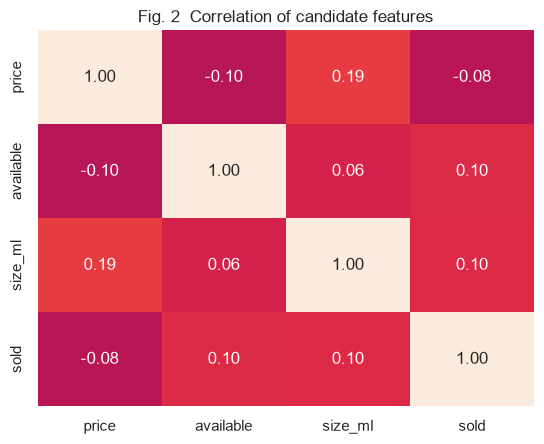

In [1009]:
# correlation of selected features
fig, ax = plt.subplots(figsize=(5.6, 4.6))
sns.heatmap(feature_matrix[['price', 'available', 'size_ml', 'sold']].corr(), annot=True, fmt=".2f", 
            vmin=-1, vmax=1, ax=ax, cbar=False)
ax.grid(False)
ax.set_title("Fig. 2  Correlation of candidate features"); fig.tight_layout(); plt.show()

### Step 4: Feature Matrix Transformation

In [1010]:
df = pd.read_csv('cleaned_data/feature_matrix.csv')
# data recheck
display(df.head())
print(
    f"Missing values count: {df.isna().sum().sum()}\n"
    f"Duplicate values count: {df.duplicated().sum().sum()}\n"
    f"Column types: {df.dtypes}",
    f"Dataset shape: {df.shape}"
)

,category,available,sold,price,size_ml
0,Eau De Parfum,39,4,3.00,100.000
1,Eau De Toilette,4,3009,3.50,100.538
2,Other,9,18882,6.65,10.000
3,Eau De Parfum,10,131,6.94,3.000
4,Eau De Parfum,10,102,6.96,100.000


Missing values count: 0
Duplicate values count: 0
Column types: category         str
available      int64
sold           int64
price        float64
size_ml      float64
dtype: object Dataset shape: (994, 5)


In [1011]:
# 1. log transform for handling skew
# without size_ml
log_cols = df.select_dtypes(include=['int64', 'float64']).columns.to_list()
log_cols.pop(-1)
skew_check = pd.DataFrame({
    'skew_raw': df[log_cols].skew(),
    'skew_log1p': np.log1p(df[log_cols]).skew(),
}).round(2)
display(skew_check)

# including size_ml
log_cols = df.select_dtypes(include=['int64', 'float64']).columns.to_list()
skew_check = pd.DataFrame({
    'skew_raw': df[log_cols].skew(),
    'skew_log1p': np.log1p(df[log_cols]).skew(),
}).round(2)
display(skew_check)

# size_ml is already symmetrical and inluding it in the log transformation rather skews it
df_log = df.copy()
df_log[log_cols] = np.log1p(df[log_cols])
display(df_log.head())

# 2. Scaling and encoding
numeric_cols = df_log.columns[1:]

scaler = StandardScaler()
X_numeric = pd.DataFrame(
    scaler.fit_transform(df_log[numeric_cols]),
    columns=numeric_cols,
    index=df_log.index
)

X_category = pd.get_dummies(df_log['category'], prefix='category', dtype=int)

X = pd.concat([X_numeric, X_category], axis=1)
print(f"Model input shape: {X.shape}")
display(X.head())
display(X.describe().T.round(2))


,skew_raw,skew_log1p
available,8.62,1.56
sold,9.72,0.49
price,2.04,0.10


,skew_raw,skew_log1p
available,8.62,1.56
sold,9.72,0.49
price,2.04,0.10
size_ml,0.05,-2.86


,category,available,sold,price,size_ml
0,Eau De Parfum,3.688879,1.609438,1.386294,4.615121
1,Eau De Toilette,1.609438,8.009695,1.504077,4.620433
2,Other,2.302585,9.846017,2.034706,2.397895
3,Eau De Parfum,2.397895,4.882802,2.071913,1.386294
4,Eau De Parfum,2.397895,4.634729,2.074429,4.615121


Model input shape: (994, 8)


,available,sold,price,size_ml,category_Cologne,category_Eau De Parfum,category_Eau De Toilette,category_Other
0,1.606456,-1.279509,-3.346292,0.246885,0,1,0,0
1,-0.662795,1.783195,-3.170878,0.252919,0,0,1,0
2,0.093622,2.661927,-2.380614,-2.271097,0,0,0,1
3,0.197632,0.286888,-2.325201,-3.419918,0,1,0,0
4,0.197632,0.168178,-2.321454,0.246885,0,1,0,0


,count,mean,std,min,25%,50%,75%,max
available,994.0,-0.00,1.00,-1.66,-0.66,0.09,0.20,4.93
sold,994.0,0.00,1.00,-2.05,-0.75,-0.17,0.72,3.17
price,994.0,0.00,1.00,-3.35,-0.68,-0.04,0.69,2.87
size_ml,994.0,0.00,1.00,-4.33,0.25,0.25,0.25,1.22
category_Cologne,994.0,0.08,0.27,0.00,0.00,0.00,0.00,1.00
category_Eau De Parfum,994.0,0.39,0.49,0.00,0.00,0.00,1.00,1.00
category_Eau De Toilette,994.0,0.46,0.50,0.00,0.00,0.00,1.00,1.00
category_Other,994.0,0.07,0.25,0.00,0.00,0.00,0.00,1.00


### Step 4: Model Training

#### 1. K-Means

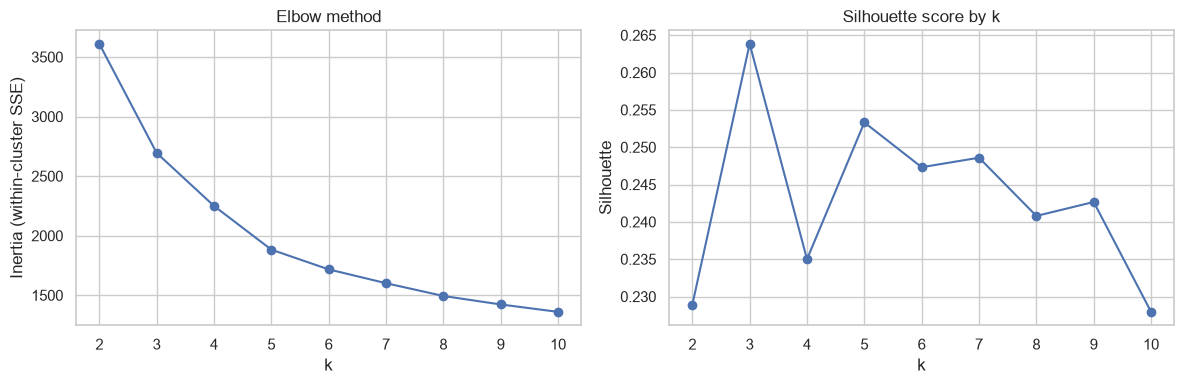

In [1012]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = kmeans.fit_predict(X)
    inertias.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X, labels))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(k_range, inertias, marker='o')
axes[0].set(title='Elbow method', xlabel='k', ylabel='Inertia (within-cluster SSE)')
axes[1].plot(k_range, sil_scores, marker='o')
axes[1].set(title='Silhouette score by k', xlabel='k', ylabel='Silhouette')
plt.tight_layout()
plt.show()

best_k = 2
kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

### 2. Hierachical Clustering (Agglomerative)

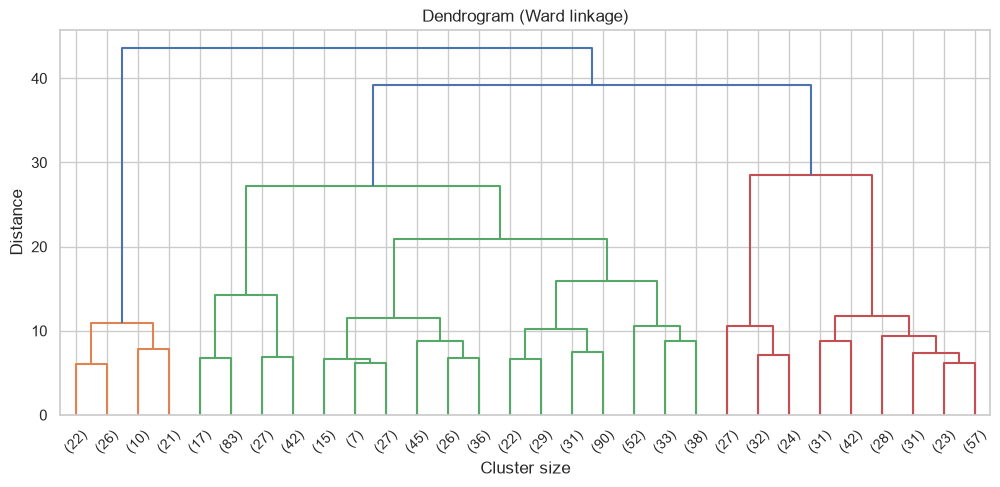

2     0.415
3     0.241
4     0.211
5     0.209
6     0.214
7     0.223
8     0.210
9     0.193
10    0.199
Name: silhouette, dtype: float64

In [1013]:
plt.figure(figsize=(12, 5))
dendrogram(linkage(X, method='ward'), truncate_mode='lastp', p=30)
plt.title('Dendrogram (Ward linkage)')
plt.xlabel('Cluster size')
plt.ylabel('Distance')
plt.show()

hier_sil = {k: silhouette_score(X, AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X))
            for k in range(2, 11)}
display(pd.Series(hier_sil, name='silhouette').round(3))

best_k_hier = 5
hier = AgglomerativeClustering(n_clusters=best_k_hier, linkage='ward')
hier_labels = hier.fit_predict(X)

#### 3. DBSCAN

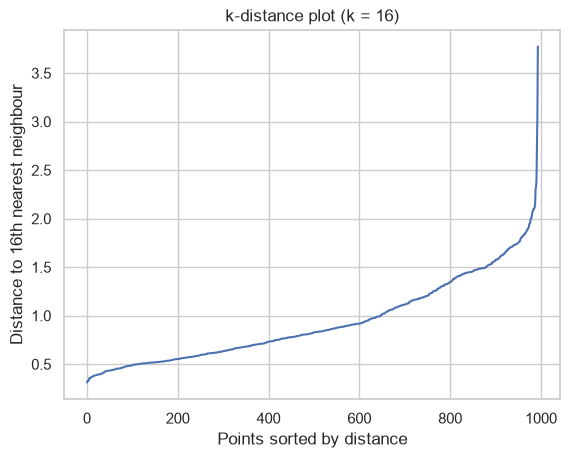

eps=0.6: clusters=2, noise points=558
eps=0.8: clusters=4, noise points=316
eps=1.0: clusters=3, noise points=237
eps=1.2: clusters=6, noise points=116


In [1014]:
min_samples = 2 * X.shape[1]
distances, _ = NearestNeighbors(n_neighbors=min_samples).fit(X).kneighbors(X)
k_dist = np.sort(distances[:, -1])

plt.plot(k_dist)
plt.title(f'k-distance plot (k = {min_samples})')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'Distance to {min_samples}th nearest neighbour')
plt.show()

# try a few eps values around the elbow
for eps in [0.6, 0.8, 1.0, 1.2]:
    labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(f"eps={eps}: clusters={n_clusters}, noise points={(labels == -1).sum()}")

best_eps = 1.0  # set from the plot and results above
dbscan_labels = DBSCAN(eps=best_eps, min_samples=min_samples).fit_predict(X)

### Comparison and Evaluation

In [1015]:
def evaluate(X, labels, name):
    mask = labels != -1  # exclude DBSCAN noise points from the metrics
    return {
        'model': name,
        'n_clusters': len(set(labels[mask])),
        'noise_points': (~mask).sum(),
        'silhouette': silhouette_score(X[mask], labels[mask]),
        'davies_bouldin': davies_bouldin_score(X[mask], labels[mask]),
        'calinski_harabasz': calinski_harabasz_score(X[mask], labels[mask]),
    }

comparison = pd.DataFrame([
    evaluate(X, kmeans_labels, 'K-Means'),
    evaluate(X, hier_labels, 'Hierarchical (Ward)'),
    evaluate(X, dbscan_labels, 'DBSCAN'),
]).round(3)
display(comparison)

,model,n_clusters,noise_points,silhouette,davies_bouldin,calinski_harabasz
0,K-Means,2,0,0.229,1.776,269.708
1,Hierarchical (Ward),5,0,0.209,1.303,294.118
2,DBSCAN,3,237,0.192,1.476,131.961


### Step 5: PCA and Visualization

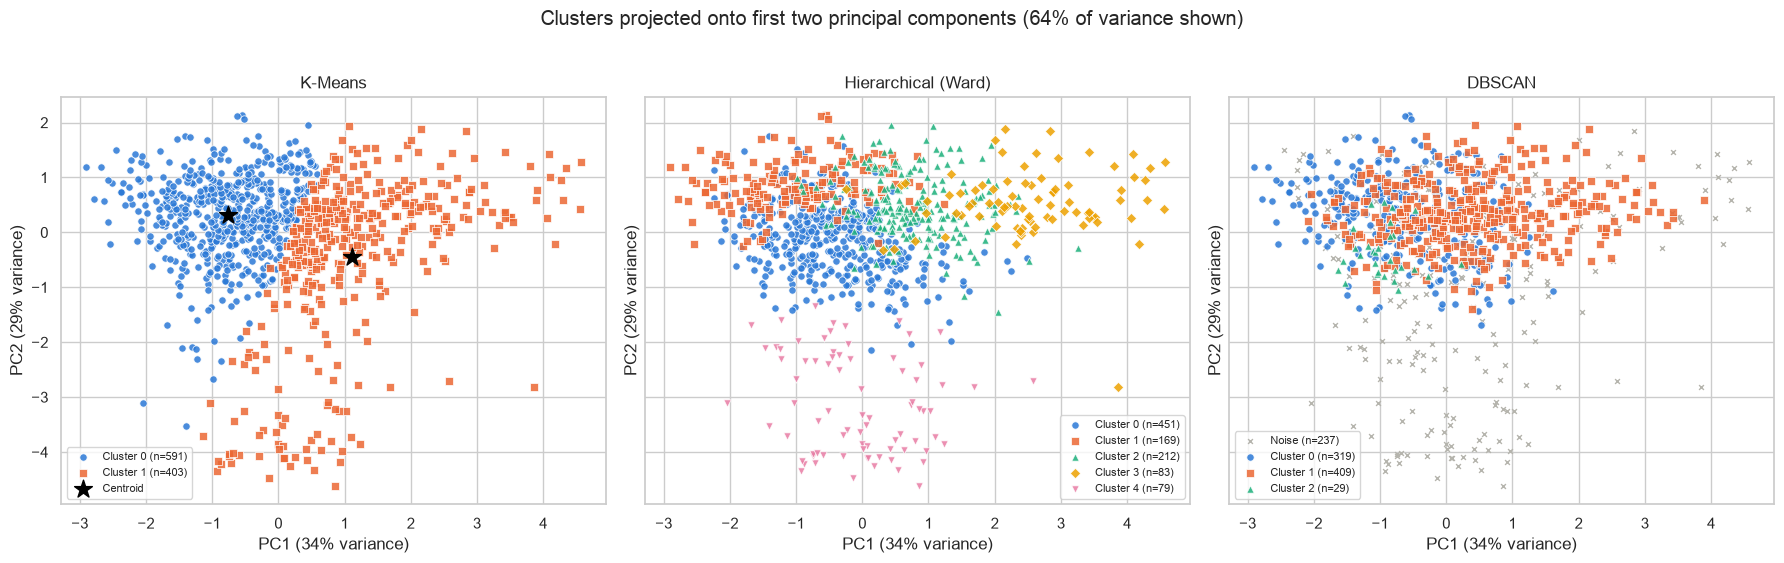

In [1016]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca.fit_transform(X)
ev = pca.explained_variance_ratio_

palette = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
markers = ['o', 's', '^', 'D', 'v', 'P']

models = {'K-Means': kmeans_labels,
          'Hierarchical (Ward)': hier_labels,
          'DBSCAN': dbscan_labels}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True, sharey=True)
for ax, (name, labels) in zip(axes, models.items()):
    for i, c in enumerate(sorted(set(labels))):
        m = labels == c
        if c == -1:   # DBSCAN noise
            ax.scatter(X_2d[m, 0], X_2d[m, 1], s=12, c='#b5b4ad', marker='x',
                       linewidths=1, label=f'Noise (n={m.sum()})')
        else:
            ax.scatter(X_2d[m, 0], X_2d[m, 1], s=28, c=palette[c % 6], marker=markers[c % 6],
                       edgecolors='white', linewidths=0.6, alpha=0.85,
                       label=f'Cluster {c} (n={m.sum()})')
    if name == 'K-Means':   # centroids projected into the same PCA space
        cent = pca.transform(pd.DataFrame(kmeans.cluster_centers_, columns=X.columns))
        ax.scatter(cent[:, 0], cent[:, 1], s=180, c='black', marker='*', label='Centroid')
    ax.set(title=name,
           xlabel=f'PC1 ({ev[0]:.0%} variance)',
           ylabel=f'PC2 ({ev[1]:.0%} variance)')
    ax.legend(fontsize=8, loc='best', frameon=True)

fig.suptitle(f'Clusters projected onto first two principal components '
             f'({ev.sum():.0%} of variance shown)', y=1.02)
plt.tight_layout()
plt.show()
